# 03 · Sensitivity analysis: extreme absorption values and vitamin C

Produces **Supplementary Table 4** and **Supplementary Figure 2**. The final model configuration
(hyperparameters fixed, no re-tuning) is refitted after excluding (A) measurements below the 1st or
above the 99th percentile of fractional absorption, (B) measurements with co-administered vitamin C,
and (C) both.

In [1]:
import os, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
from sklearn.model_selection import KFold, train_test_split
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

RANDOM_STATE = 42
FINAL_PARAMS = {"colsample_bytree": 0.7, "learning_rate": 0.05, "max_depth": 8, "n_estimators": 400, "subsample": 0.8}
DROP_COLS = ["Order", "Study", "Gender", "Idold", "BW", "BH", "Alpha glycoprotein", "Site",
         "Meal or Supplement", "Meat protein", "Milk protein", "Tea dose", "MC.last",
         "MC.freq", "MC.duration", "MC.percentage", "GOS dose ", "Ethnicity", "sTfR"]
os.makedirs("../results", exist_ok=True)
os.makedirs("../figures/panels", exist_ok=True)

## 1. Data and helper functions

In [2]:
raw = pd.read_excel("../data/pooled_dataset.xls")


def prepare(df_raw, keep=None):
    """Same preprocessing as notebook 01; keep = optional boolean row selection on the raw data."""
    df = df_raw.copy() if keep is None else df_raw[keep].copy()
    df = df.drop(columns=DROP_COLS)
    df["Meal type"] = df["Meal type"].fillna("Supplement")
    df["Isotope"] = df["Isotope"].fillna("Unknown")
    for col in df.columns:
        if df[col].dtype != float:
            df[col] = df[col].astype("category").cat.codes
    return df[df.isnull().sum(axis=1) < 14]

In [3]:
def smape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    return np.mean(2.0 * np.abs(y_pred - y_true) / (np.abs(y_true) + np.abs(y_pred) + eps))



def fit_and_eval(df, label):
    """Final hyperparameters (no re-tuning), 80:20 split; test metrics and five-fold CV R² in the training set."""
    y = np.log10(df["Fe absorption (%)"] + 1)
    X = df[[c for c in df.columns if c != "Fe absorption (%)"]]
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
    model = xgb.XGBRegressor(objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1, **FINAL_PARAMS)
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    cv_r2 = []
    cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    Xt, yt = X_train.reset_index(drop=True), y_train.reset_index(drop=True)
    for tr, va in cv.split(Xt):
        m = xgb.XGBRegressor(objective="reg:squarederror", random_state=RANDOM_STATE, n_jobs=-1, **FINAL_PARAMS)
        m.fit(Xt.iloc[tr], yt.iloc[tr])
        cv_r2.append(r2_score(yt.iloc[va], m.predict(Xt.iloc[va])))

    return {"Analysis": label, "n": len(df),
            "Test RMSE": root_mean_squared_error(y_test, y_pred), "Test MAE": mean_absolute_error(y_test, y_pred),
            "Test R2": r2_score(y_test, y_pred), "Test sMAPE": smape(y_test, y_pred),
            "CV R2 mean": np.mean(cv_r2), "CV R2 SD": np.std(cv_r2, ddof=1),
            "y_test": y_test.values, "y_pred": y_pred}

## 2. Baseline and sensitivity analyses

In [4]:
fa = raw["Fe absorption (%)"]
p1, p99 = np.nanpercentile(fa, [1, 99])
keep_trim = (fa >= p1) & (fa <= p99)
keep_novitc = ~(raw["Vitamin C dose"].fillna(0) > 0)
print(f"1st percentile {p1:.2f}%, 99th percentile {p99:.2f}%")

results = [
    fit_and_eval(prepare(raw), "Baseline (full data)"),
    fit_and_eval(prepare(raw, keep_trim), "A: extreme values excluded"),
    fit_and_eval(prepare(raw, keep_novitc), "B: vitamin C excluded"),
    fit_and_eval(prepare(raw, keep_trim & keep_novitc), "C: A and B combined"),
]
supp_table4 = pd.DataFrame([{k: v for k, v in r.items() if k not in ("y_test", "y_pred")} for r in results]).round(3)
print(supp_table4.to_string(index=False))
supp_table4.to_csv("../results/supp_table4_sensitivity.csv", index=False)

1st percentile 0.37%, 99th percentile 66.13%


                  Analysis    n  Test RMSE  Test MAE  Test R2  Test sMAPE  CV R2 mean  CV R2 SD
      Baseline (full data) 5058      0.206     0.160    0.757       0.200       0.722     0.028
A: extreme values excluded 4957      0.213     0.165    0.715       0.193       0.712     0.014
     B: vitamin C excluded 3783      0.217     0.165    0.699       0.191       0.710     0.015
       C: A and B combined 3744      0.209     0.162    0.719       0.186       0.700     0.009


## 3. Supplementary Figure 2: predicted vs observed, baseline vs extreme values excluded

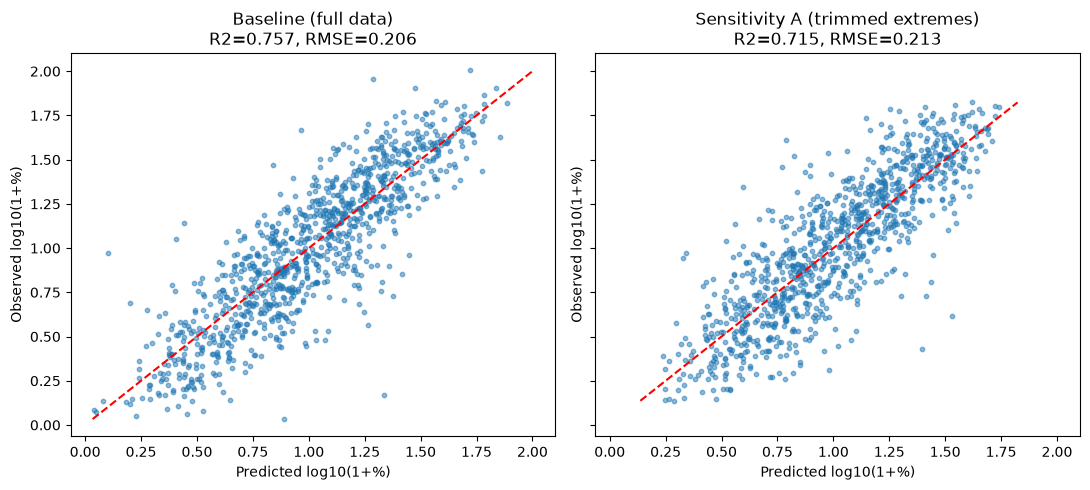

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharex=True, sharey=True)
for ax, r, title in zip(axes, results[:2], ["Baseline (full data)", "Sensitivity A (trimmed extremes)"]):
    ax.scatter(r["y_pred"], r["y_test"], s=10, alpha=0.5)
    lims = [min(r["y_pred"].min(), r["y_test"].min()), max(r["y_pred"].max(), r["y_test"].max())]
    ax.plot(lims, lims, "r--")
    ax.set_xlabel("Predicted log10(1+%)"); ax.set_ylabel("Observed log10(1+%)")
    ax.set_title(f"{title}\nR2={r['Test R2']:.3f}, RMSE={r['Test RMSE']:.3f}")
plt.tight_layout()
plt.savefig("../figures/panels/SuppFig2.png", dpi=150)
plt.show()